Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded OK")

Libraries loaded OK


Step 2: Load the Raw Dataset

In [2]:
df = pd.read_csv('../datasets/association/raw_online_retail.csv', encoding='ISO-8859-1')
print("Shape:", df.shape)
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


 Step 3: Initial Data Inspection

In [3]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Step 4: Profile Invalid Records

In [4]:
inv = df['InvoiceNo'].astype(str)
print("Cancelled rows (start with C):", inv.str.startswith('C').sum())
print("Quantity <= 0:", (df['Quantity'] <= 0).sum())
print("UnitPrice <= 0:", (df['UnitPrice'] <= 0).sum())

Cancelled rows (start with C): 9288
Quantity <= 0: 10624
UnitPrice <= 0: 2517


Step 5: Clean the Data

In [5]:
df_clean = df.copy()
print("Start:", len(df_clean))

df_clean['Description'] = df_clean['Description'].str.strip()
df_clean = df_clean.dropna(subset=['InvoiceNo', 'Description'])
print("After dropping missing Description:", len(df_clean))

df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]
print("After removing cancelled (C):", len(df_clean))

df_clean = df_clean[df_clean['Quantity'] > 0]
print("After removing Quantity <= 0:", len(df_clean))

df_clean = df_clean[df_clean['UnitPrice'] > 0]
print("After removing UnitPrice <= 0:", len(df_clean))

Start: 541909
After dropping missing Description: 540455
After removing cancelled (C): 531167
After removing Quantity <= 0: 530693
After removing UnitPrice <= 0: 530104


Step 6: Remove Non-Product Items

In [6]:

df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str).str.strip()
bad_invoices = df_clean[~df_clean['InvoiceNo'].str.match(r'^[CA]?\d{6}$')]
print("Invoices not matching expected format:", len(bad_invoices))


df_clean['InvoiceNo'] = df_clean['InvoiceNo'].str.extract(r'([CA]?\d{6})\s*$')[0]
df_clean = df_clean.dropna(subset=['InvoiceNo'])
still_bad = (~df_clean['InvoiceNo'].str.match(r'^[CA]?\d{6}$')).sum()
print("Invoices still not matching after fix:", still_bad)

df_clean['StockCode'] = df_clean['StockCode'].astype(str).str.strip()

non_product_codes = ['POST', 'DOT', 'M', 'D', 'C2', 'BANK CHARGES',
                     'AMAZONFEE', 'S', 'B', 'CRUK', 'PADS']
non_product_desc = ['POSTAGE', 'DOTCOM POSTAGE', 'MANUAL', 'BANK CHARGES',
                    'DISCOUNT', 'AMAZON FEE', 'CARRIAGE', 'SAMPLES',
                    'CRUK COMMISSION', 'ADJUST BAD DEBT']

before = len(df_clean)
df_clean = df_clean[~df_clean['StockCode'].str.upper().isin(non_product_codes)]
df_clean = df_clean[~df_clean['Description'].str.upper().isin(non_product_desc)]
print("\nRemoved non-product rows:", before - len(df_clean))


before = len(df_clean)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('A')]
print("Removed 'A' (bad debt) invoices:", before - len(df_clean))


print("\nAfter removing non-product items:", len(df_clean))
print("Unique Invoices:", df_clean['InvoiceNo'].nunique())
print("Unique Products:", df_clean['Description'].nunique())

Invoices not matching expected format: 9
Invoices still not matching after fix: 0

Removed non-product rows: 2315
Removed 'A' (bad debt) invoices: 0

After removing non-product items: 527789
Unique Invoices: 19773
Unique Products: 4006


Step 7: Validate the Cleaning

In [7]:
assert (df_clean['Quantity'] <= 0).sum() == 0
assert (df_clean['UnitPrice'] <= 0).sum() == 0
assert df_clean['InvoiceNo'].str.startswith('C').sum() == 0
assert df_clean['InvoiceNo'].str.startswith('A').sum() == 0
assert df_clean['InvoiceNo'].str.match(r'^\d{6}$').all()
assert (~df_clean['StockCode'].str.upper().isin(non_product_codes)).all()
assert (~df_clean['Description'].str.upper().isin(non_product_desc)).all()

print("Data Cleaning Integrity Verified!")
print()
print(df_clean['Description'].value_counts().head(15))

Data Cleaning Integrity Verified!

Description
WHITE HANGING HEART T-LIGHT HOLDER    2323
JUMBO BAG RED RETROSPOT               2112
REGENCY CAKESTAND 3 TIER              2017
PARTY BUNTING                         1706
LUNCH BAG RED RETROSPOT               1594
ASSORTED COLOUR BIRD ORNAMENT         1489
SET OF 3 CAKE TINS PANTRY DESIGN      1399
PACK OF 72 RETROSPOT CAKE CASES       1370
LUNCH BAG  BLACK SKULL.               1328
NATURAL SLATE HEART CHALKBOARD        1263
JUMBO BAG PINK POLKADOT               1238
HEART OF WICKER SMALL                 1226
PAPER CHAIN KIT 50'S CHRISTMAS        1200
JUMBO STORAGE BAG SUKI                1197
JUMBO SHOPPER VINTAGE RED PAISLEY     1190
Name: count, dtype: int64


 Step 8: Visualize and Save

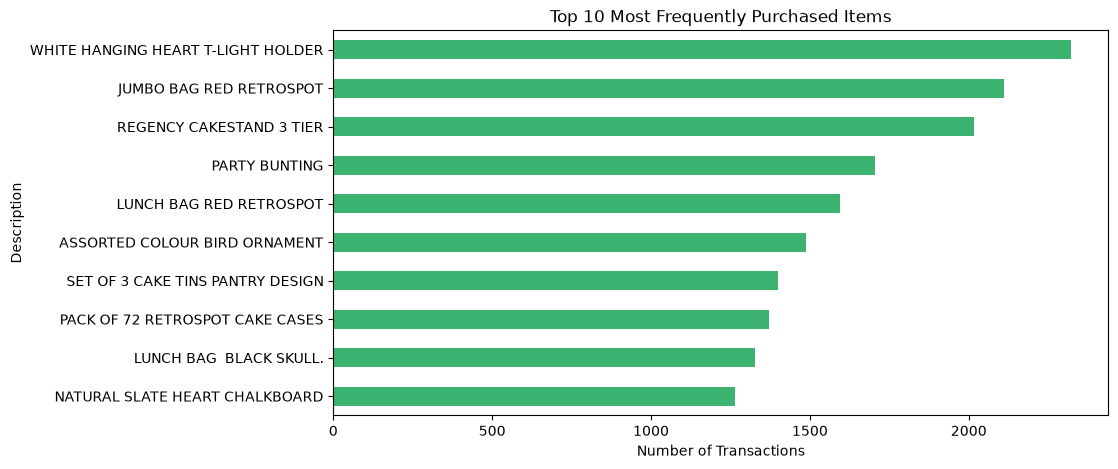

Saved: (527789, 8)


In [8]:
import os

os.makedirs('../results/association', exist_ok=True)
os.makedirs('../datasets/association', exist_ok=True)

top_items = df_clean['Description'].value_counts().head(10)
plt.figure(figsize=(10, 5))
top_items.plot(kind='barh', color='mediumseagreen')
plt.title('Top 10 Most Frequently Purchased Items')
plt.xlabel('Number of Transactions')
plt.gca().invert_yaxis()
plt.savefig('../results/association/top_10_products.png', bbox_inches='tight')
plt.show()

df_clean.to_csv('../datasets/association/cleaned_retail_transactions.csv', index=False)
print("Saved:", df_clean.shape)

In [9]:
import time

def build_basket_matrix(cleaned_data_path: str, country: str = 'United Kingdom',
                        min_item_frequency: int = 15) -> pd.DataFrame:
    df = pd.read_csv(cleaned_data_path, dtype={'InvoiceNo': str, 'StockCode': str})

    if country and 'Country' in df.columns:
        df = df[df['Country'] == country]

    item_counts = df['Description'].value_counts()
    frequent_items = item_counts[item_counts >= min_item_frequency].index
    df = df[df['Description'].isin(frequent_items)]

    basket = (df.groupby(['InvoiceNo', 'Description'])['Quantity']
              .sum().unstack().fillna(0))

    basket_binary = (basket > 0)
    basket_binary = basket_binary[basket_binary.sum(axis=1) >= 2]

    print(f"Basket Matrix Shape: {basket_binary.shape} (Transactions x Products)")
    return basket_binary


start = time.time()
basket = build_basket_matrix(
    '../datasets/association/cleaned_retail_transactions.csv',
    country='United Kingdom',
    min_item_frequency=15
)
print("Time (s):", round(time.time() - start, 1))
print("Shape:", basket.shape)

Basket Matrix Shape: (16458, 2991) (Transactions x Products)
Time (s): 27.9
Shape: (16458, 2991)


In [10]:
assert basket.isin([True, False, 0, 1]).all().all()
assert (basket.sum(axis=1) >= 2).all()
print("Index name:", basket.index.name)
print("Dtypes:", basket.dtypes.unique())
print("Min items in an invoice:", basket.sum(axis=1).min())
print("Basket Matrix Passed All Validation Tests!")

Index name: InvoiceNo
Dtypes: [dtype('bool')]
Min items in an invoice: 2
Basket Matrix Passed All Validation Tests!


In [11]:
basket.iloc[:5, :8]

Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536372,False,False,False,False,False,False,False,False


In [12]:
basket.to_pickle('../datasets/association/basket_matrix.pkl')
print("Saved basket_matrix.pkl")

Saved basket_matrix.pkl
